# Lesson 3, Part 4

Here are helper functions carried forward from earlier parts.

In [1]:
# Helper functions carried forward from earlier parts
%pip install ipycc matplotlib
from ipycc.turtle import Turtle, showscreen, clearscreen

def plot_xy(x, y=None, color='black'):
    if type(y) is str:
        pen_color, y = (y, None)
    if y == None:
        x, y = zip(*x)
    t = Turtle()
    t.speed('fastest')
    t.color(color)
    t.penup()
    t.goto(x[0], y[0])
    t.pendown()
    for i in range(1, len(x)):
        t.goto(x[i], y[i])

def linear_spacing(start, stop, num):
    interval = (stop - start) / (num - 1)
    return [start + i * interval for i in range(num)]

Let's extend our cubic formula to encompass any polynomial. 
Instead of describing the constant coefficients with letters *a,b,c,...*, 
let's gather them into a list 'coef', where coef[k] is the multiplier on *x*<sup>k</sup>. 
This reverses the order we used before; e.g., what was '*a*' for a cubic is now coef[3].

In [2]:
def polynomial(x_val,coef):
    # return sum([coef[k] * x_val**k for k in range(len(coef))]) 
    # alternative expression that is more efficient
    poly = coef[-1]
    for c in coef[-2::-1]:
        poly = poly * x_val  + c
    return poly

# test
coef = [0,0,0,0,1]
x = [1,2,3,4]
y = [polynomial(val,coef) for val in x]
print('x =',x,', x**4 =',y)

x = [1, 2, 3, 4] , x**4 = [1, 16, 81, 256]


For every whole number *k*, *x*<sup>k</sup> has derivative *kx*<sup>*k*-1</sup>, while constants *c* have derivative 0. 
Hence the derivatives of polynomials have simple formulas. 
The second and third methods make use of empty lists, which have length 0.

In [3]:
def deriv_polynomial_orig(x_val,coef):
    return sum([coef[k] * k * x_val**(k-1) for k in range(len(coef))])

def deriv_polynomial_better(x_val,coef):    # more efficient alternative
    coef_deriv = [coef[k] * k  for k in range(1,len(coef))]
    if len(coef_deriv)==0:      # derivative of constant = 0
        return 0
    return polynomial(x_val,coef_deriv)

def deriv_polynomial_alt(x_val,coef):    # crisper alternative
    coef_deriv = [coef[k] * k  for k in range(1,len(coef))]
    return polynomial(x_val,coef_deriv) if len(coef_deriv)>0 else 0

x_val,coef = 2,[0,0,0,0,1]
y_val0 = deriv_polynomial_orig(x_val,coef)
y_val1 = deriv_polynomial_better(x_val,[0,0,0,0,1])
y_val2 = deriv_polynomial_alt(x_val,[0,0,0,0,1])
print("Do all three methods yield same derivative?", y_val0 == y_val1 == y_val2)
print('Derivative of x**4 = 4x**3, which at x =',x_val,'equals',y_val2)

Do all three methods yield same derivative? True
Derivative of x**4 = 4x**3, which at x = 2 equals 32


The integrals of polynomials are similarly easy to compute once we apply the Fundamental Theorem.

In [4]:
def integral_polynomial_orig(x_val,coef,constant=0):
    return sum([(coef[k] / (k+1)) * x_val**(k+1) + constant for k in range(len(coef))])

def integral_polynomial_better(x_val,coef,constant=0):  # more efficient alternatives 
    coef_integral = [constant]
    for k in range(len(coef)):
        coef_integral.append(coef[k] / (k+1))
    return polynomial(x_val,coef_integral)

x_val,coef = 3,[0,0,0,4]
y_val = integral_polynomial_better(x_val,coef,0)
print('Integral of 4x**3 equals x**4 + constant c, which at x =',x_val,'equals',y_val,'+c')

Integral of 4x**3 equals x**4 + constant c, which at x = 3 equals 81.0 +c


These formulas apply for nearly any power of *x*. The only exception is the integral of *x*<sup>-1</sup> = 1/*x*, where the formula divides by 0. 
Let's form two lists: one for powers *p* and one for the coefficients on the various *x*<sup>*p*</sup>.

In [5]:
def sum_power_fn(x_val,coef,power):
    return sum([coef[k] * x_val**power[k] for k in range(len(coef))])
    # return sum([c * x_val**p for c,p in zip(coef,power)])   # does the same thing using zip and is easier to read 

def deriv_sum_power_fn(x_val,coef,power):
    coef_deriv = []
    power_deriv = []       # don't set power_deriv=coef_deriv=[] or they will forever be equal 
    for k in range(len(coef)):
        if power[k]==0:    # derivative of constant is zero
            continue       # so skip to next index
        power_deriv.append(power[k]-1)
        coef_deriv.append(coef[k] * power[k])
    return sum_power_fn(x_val,coef_deriv,power_deriv)

def integral_sum_power_fn(x_val,coef,power,constant=0):
    power_integral = [0]
    coef_integral = [constant]
    for k in range(len(coef)):
        p = power[k] + 1
        if p==0:
            return "Can't yet solve this"
        power_integral.append(p)
        coef_integral.append(coef[k] / p)
    return sum_power_fn(x_val,coef_integral,power_integral)

x_val,coef,power = 4,[1],[0.5]
y = sum_power_fn(x_val,coef,power)
dydx = deriv_sum_power_fn(x_val,coef,power)
integral_y = integral_sum_power_fn(x_val,coef,power)
print('x =',x_val,': y = sqrt(x)=',y,'\nderiv = 0.5/sqrt(x) =',dydx,'\nintegral = (x**1.5)/1.5 =',round(integral_y,5))
x_val,coef,power = 0.5,[1],[-2]
y = sum_power_fn(x_val,coef,power)
dydx = deriv_sum_power_fn(x_val,coef,power)
integral_y = integral_sum_power_fn(x_val,coef,power)
print('\nx =',x_val,': y = (1/x)**2=',y,'\nderiv = -2*(1/x)**3 =',dydx,'\nintegral = -1/x =',integral_y)

x = 4 : y = sqrt(x)= 2.0 
deriv = 0.5/sqrt(x) = 0.25 
integral = (x**1.5)/1.5 = 5.33333

x = 0.5 : y = (1/x)**2= 4.0 
deriv = -2*(1/x)**3 = -16.0 
integral = -1/x = -2.0


The impact of power *p* in *x*<sup>*p*</sup> is best appreciated through charts. 
Unfortunately, some values will extend way off the standard turtle display or the chart may look too flat to detect changes, and
there is no clearly visible scale to help us adjust. This example illustrates all three problems.

In [6]:
showscreen()
clearscreen()
coef = [0,0,0,0,3E-7]
x = linear_spacing(-200,200,100)
y = [polynomial(val,coef) for val in x]
plot_xy(x,y)  #  looks near-flat in middle but extends off screen

Canvas(height=800, layout=Layout(height='400px', width='400px'), width=800)

Fortunately, Python has a module **matplotlib.pyplot** that automatically plots a full chart with numbered axes. 
By convention, it is imported as **plt**.

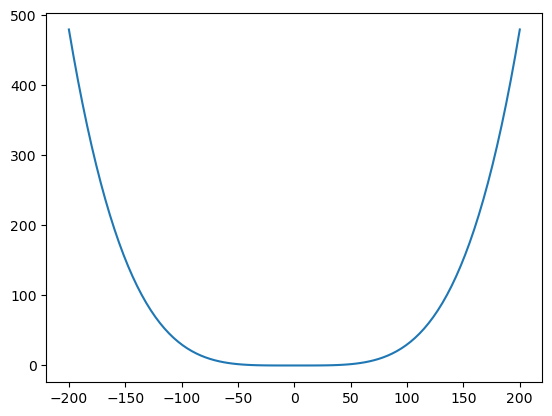

In [7]:
import matplotlib.pyplot as plt  # lets us access matplotlib.pyplot using 'plt.' prefix

coef = [0,0,0,0,3E-7]
x = linear_spacing(-200,200,100)
y = [polynomial(val,coef) for val in x]
plt.plot(x,y)     # creates a plot of y versus x
plt.show()        # displays the graph

Here is how to chart whole number powers of *x* with labels. 
Pyplot automatically sets different colors.

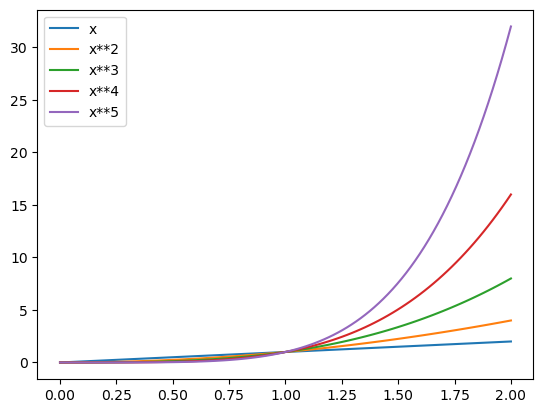

In [8]:
x = linear_spacing(0,2,100)
# various whole number power functions and ways to express them
y1 = [val for val in x]
y2 = [val * val for val in x]
y3 = [val**3 for val in x]   
y4 = [val**4 for val in x]    
y5 = [val**5 for val in x]
# plot (x,y) pairs and label them, with colors shifting automatically
plt.plot(x, y1, label='x') 
plt.plot(x, y2, label='x**2')   
plt.plot(x, y3, label='x**3')
plt.plot(x, y4, label='x**4')
plt.plot(x, y5, label='x**5')
plt.legend()   # displays legend with labels
plt.show()     # displays the graph

Let us redo on a shorter interval to see the inversion in ordering for *x* < 1.

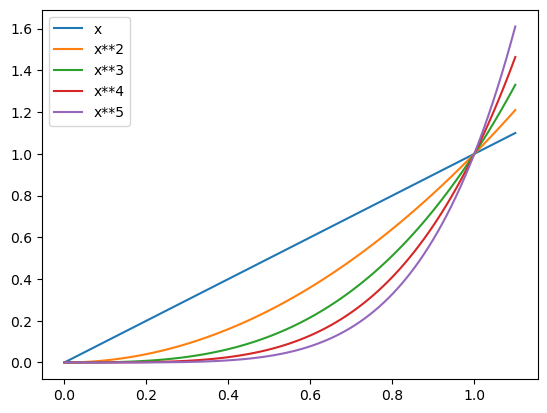

In [9]:
x = linear_spacing(0,1.1,100)  # the previous chart used (0,2,100)
# various whole number power functions
y1 = [val for val in x]
y2 = [val * val for val in x]
y3 = [val**3 for val in x]   
y4 = [val**4 for val in x]    
y5 = [val**5 for val in x]
# plot (x,y) pairs and label them
plt.plot(x, y1, label='x') 
plt.plot(x, y2, label='x**2')   
plt.plot(x, y3, label='x**3')
plt.plot(x, y4, label='x**4')
plt.plot(x, y5, label='x**5')
plt.legend() 
plt.show()

Let us now plot negative powers of *x*. 
To distinguish the plots for *x*>0.5, raise the lower bound on *x*.

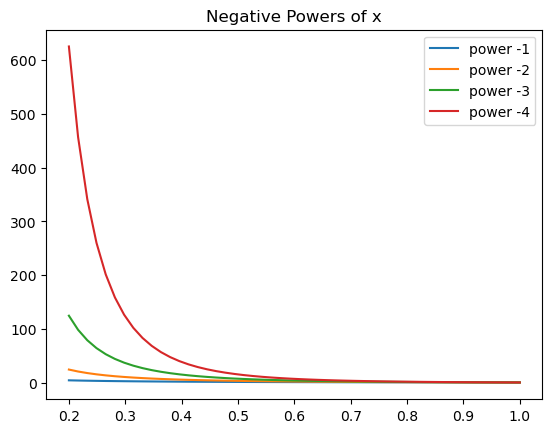

In [10]:
x = linear_spacing(0.2,1,50)         # bound x away from origin to restrain maximum y
# x = linear_spacing(0.5,1,50)       # alternative
y1 = [1/val for val in x]
y2 = [1/(val*val) for val in x]  
y3 = [1/val**3 for val in x]
y4 = [val**-4 for val in x]
plt.title('Negative Powers of x')    # display title given in parentheses
plt.plot(x,y1,x,y2,x,y3,x,y4)        # alternative way to plot multiple series    
plt.legend(['power -1','power -2','power -3','power -4'])  # alternative way to display legend
plt.show()

Don't like the default chart style? 
As illustrated here, there are others, 
and individual features can be added or modified.
Try *design*=1,2 or 3.

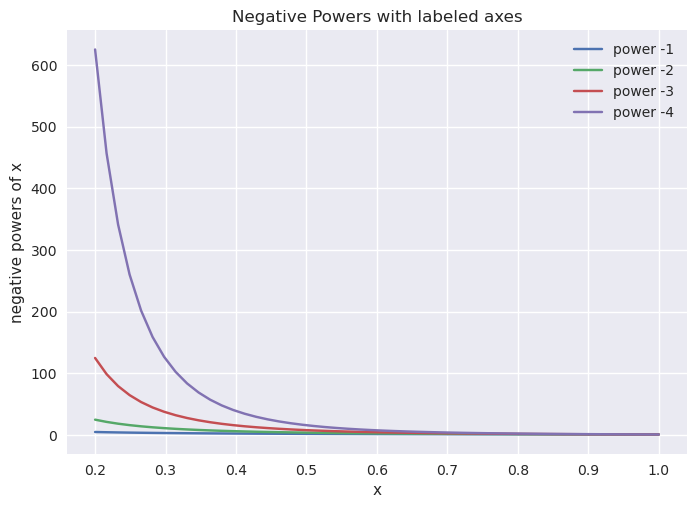

In [15]:
plt.style.use('seaborn-v0_8')           # switch to stylesheet seaborn'

design = 1     # try 1,2,3 
x = linear_spacing(0.2,1,50)
y1 = [1/val for val in x]
y2 = [1/(val*val) for val in x]  
y3 = [1/val**3 for val in x]
y4 = [val**-4 for val in x]

if design == 1:
    plt.title('Negative Powers with labeled axes')
    plt.plot(x,y1,x,y2,x,y3,x,y4)        
    plt.legend(['power -1','power -2','power -3','power -4'])
    plt.xlabel('x')                       # places label on x-axis
    plt.ylabel('negative powers of x')    # places label on y-axis
elif design == 2:
    plt.title('Another version of Negative Powers')
    plt.plot(x,y1,label='power -1')       
    plt.plot(x,y2,'--',label='power -2')  # plots with dashed lines
    plt.plot(x,y3,':',label='power -3')   # plots with dotted lines
    plt.plot(x,y4,'-.',label='power -4')  # plots with dash-dots
    plt.legend()
elif design == 3:
    plt.style.use('default')       # switch back to default stylesheet
    plt.title('Reciprocal of x')   # prepare new figure
    plt.fill_between(x,y1,0)       # fills area between y1 and y-axis 
    plt.xlabel('x')
    plt.ylabel('1/x')
plt.show()

Lets plot fractional powers (roots) of *x*. 
The plots get jagged close to *x* = 0.

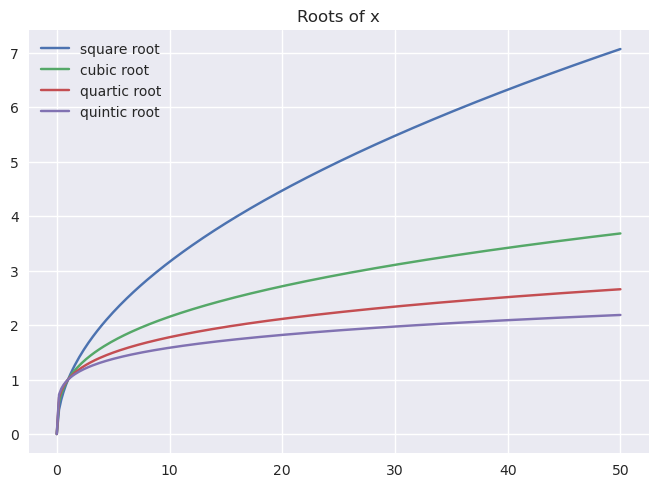

In [17]:
x = linear_spacing(0,50,251)   # intervals of 0.2
y1 = [val for val in x]
y2 = [val**(1/2) for val in x]
y3 = [val**(1/3) for val in x]
y4 = [val**(1/4) for val in x]
y5 = [val**(1/5) for val in x]
#plt.style.use('seaborn-notebook')
plt.title('Roots of x')
plt.plot(x,y2,x,y3,x,y4,x,y5)
plt.legend(['square root','cubic root','quartic root','quintic root'])
plt.show()

Let's plot roots of *x* < 1 on a finer grid. The curves still get jagged for tiny *x*, which signals very high and fast-changing derivatives.

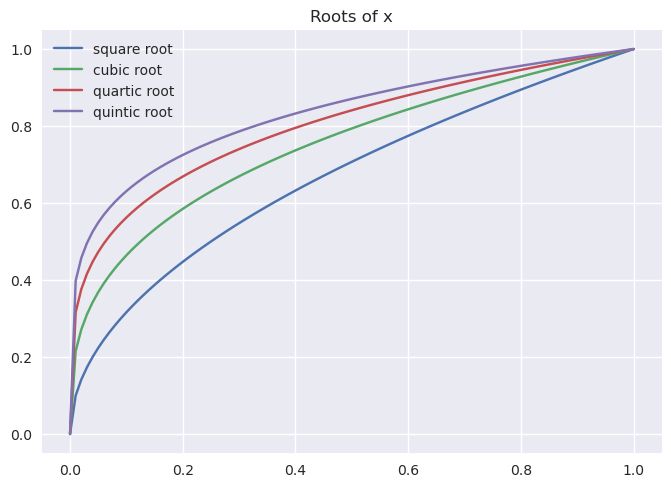

In [18]:
x = linear_spacing(0,1,101)   # intervals of 0.01
y1 = [val for val in x]
y2 = [val**(1/2) for val in x]
y3 = [val**(1/3) for val in x]
y4 = [val**(1/4) for val in x]
y5 = [val**(1/5) for val in x]
plt.title('Roots of x')
plt.plot(x,y2,x,y3,x,y4,x,y5)
plt.legend(['square root','cubic root','quartic root','quintic root'])
plt.show()

The code here plots a root of *x* and its derivative. It looks strange because the scales of the two series are so different.

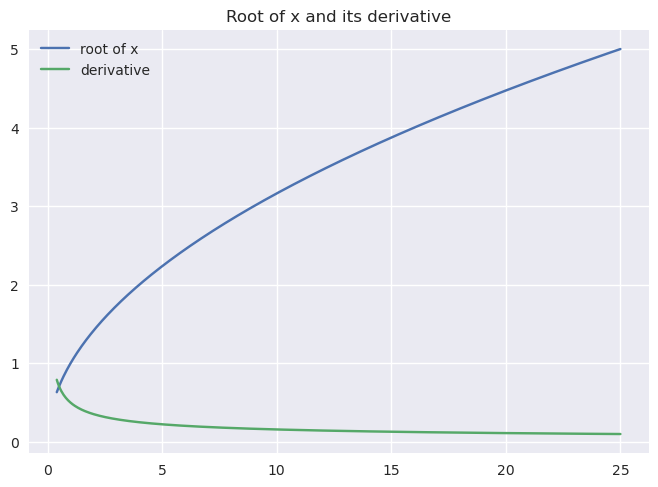

In [19]:
def root_and_deriv(num_root,xmin,xmax):
    x = linear_spacing(xmin,xmax,500)
    coef = [1]
    power = [1/num_root]
    y = [sum_power_fn(val,coef,power) for val in x]
    dydx = [deriv_sum_power_fn(val,coef,power) for val in x]
    return x,y,dydx

def plot_root_deriv(num_root,xmin,xmax):
    x,y,dydx = root_and_deriv(num_root,xmin,xmax)
    plt.title('Root of x and its derivative')
    plt.plot(x,y,x,dydx)
    plt.legend(['root of x','derivative'])
    plt.show()

xmin,xmax = 0.4,25
plot_root_deriv(2,xmin,xmax)

One remedy plots root and derivative on separate charts and stacks them. 
It uses the command **plt.subplot**(*nrows,ncols,ix*) to define a grid
of *nrows* rows and *ncols* columns and place the chart at index *ix*.
Unlike standard Python convention, indices starts at 1 rather than 0.

In this example, we stack the charts vertically using 
inputs (2,1,1) and (2,1,2), which can also be written (211) and (212). 
To stack horizontally, use inputs (1,2,1) and (1,2,2).

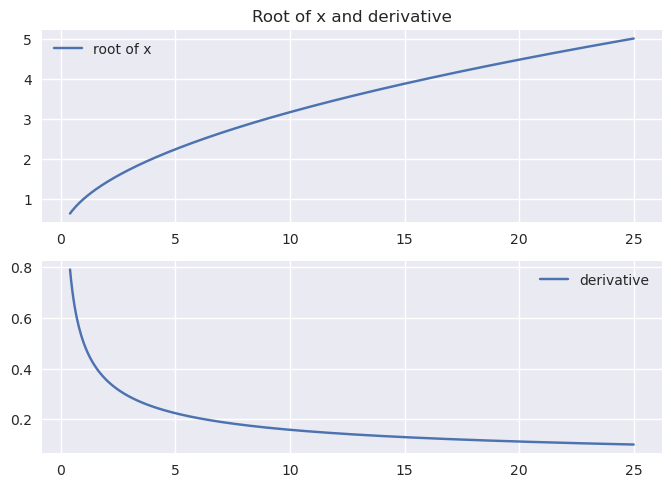

In [20]:
def plot_root_deriv_alt(num_root,xmin,xmax):
    x,y,dydx = root_and_deriv(num_root,xmin,xmax)
    # divide display into 2 rows and 1 column with chart in position 1
    plt.subplot(2,1,1)    # subplot(211) will do same thing
    plt.title('Root of x and derivative')
    plt.plot(x,y,label='root of x')
    plt.legend()
    plt.subplot(2,1,2)    # place next chart in second position
    plt.plot(x,dydx,label='derivative')
    plt.legend()
    plt.show()
    
xmin,xmax = 0.4,25
plot_root_deriv_alt(2,xmin,xmax)

We can the plots more informative by flagging the root they apply to. 
To do that, convert the number into a string using **str** and concatenate strings using **+**.

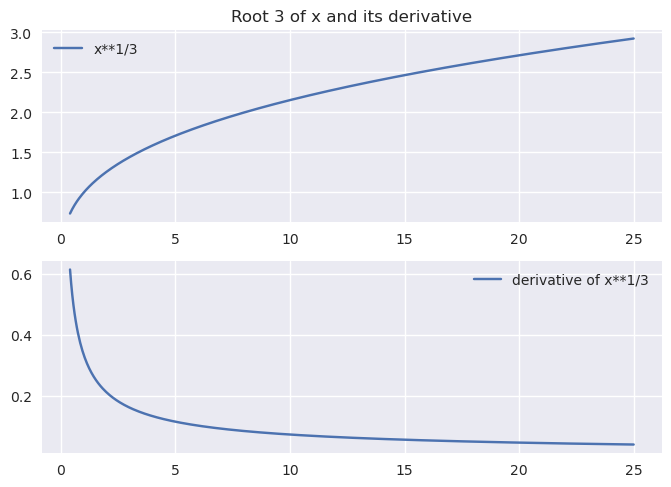

In [21]:
def plot_root_deriv_better(num_root,xmin,xmax):
    x,y,dydx = root_and_deriv(num_root,xmin,xmax)
    str_root = str(num_root)        # converts num_root into string
    plt.subplot(2,1,1)
    title_root = 'Root ' + str_root + ' of x and its derivative'  # concatenates three strings
    plt.title(title_root)  
    label_y = 'x**1/' + str_root    # concatenates two strings
    plt.plot(x,y,label=label_y)
    plt.legend()
    plt.subplot(2,1,2)              # place next chart in second position
    label_dydx = 'derivative of x**1/' + str_root
    plt.plot(x,dydx,label=label_dydx)
    plt.legend()
    plt.show()
    
xmin,xmax = 0.4,25
plot_root_deriv_better(3,xmin,xmax)